# LightGBM with weather vs AutoETS

**Question.** Does a gradient-boosting model that sees the weather forecast beat the univariate AutoETS model from `forecast.ipynb` on 48-hour generation forecasts?

**Short answer** (numbers from the run below; skill = RMSE / seasonal-naive RMSE, lower is better):
- **Cross-validation:** LightGBM is the best model over 48 hours (skill 0.83 vs 1.03 for AutoETS). AutoETS is as good on day 1 (0.84) but falls apart on day 2 (1.19).
- **Final holdout:** no model beats seasonal naive on day 1 (LightGBM 1.28, AutoETS 1.84). LightGBM keeps an edge on day 2 (0.88) and ends level with naive over 48 hours (1.00).
- **Intervals:** LightGBM has the best Winkler score (1052 vs 1478 for naive) with 94% coverage, but day 2 is under-covered (89%).
- **Weather:** most of LightGBM's skill comes from past-generation profiles. Weather adds a measurable gain mainly on day 2 (Section 6).

**Models**

| Model | Inputs | Training window |
|---|---|---|
| LightGBM + weather\* | 7 weather columns, calendar, past generation | 180 days |
| AutoETS | `log(y)`, additive error/trend/season, 24-hour season | 46 days |
| Seasonal naive | last observed day, repeated twice | — |

\* **Optimistic weather.** Historical evaluation feeds LightGBM the *observed* weather from `data/train.csv`, not the forecast that would have been available. Section 6.3 estimates how much accuracy this hides.

**Contents**
1. Data: what the series looks like and why weather should help
2. Evaluation design: rolling origins, CV and holdout
3. Features
4. Cross-validation
5. Prediction intervals and the final holdout
6. What drives LightGBM
7. Forecast for the next 48 hours
8. Summary and conclusions

Run `uv sync` and open from the project root or `notebooks/`. Helper functions live in `src/final/lgbm_baseline.py`.

In [1]:
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', message='IProgress not found')
warnings.filterwarnings('ignore', category=FutureWarning)

import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from final.lgbm_baseline import (
    DAY, DAY_PARTS, H, MODEL_COLORS, MODEL_NAMES, PARTS, WEATHER_COLUMNS,
    autoets, calibrate_halfwidths, interval, mae, make_features,
    plot_window_grid, rmse, seasonal_naive, winkler,
)

plt.rcParams.update({
    'figure.figsize': (11, 4),
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
pd.set_option('display.precision', 2)

ROOT = Path.cwd() if (Path.cwd() / 'data/train.csv').exists() else Path.cwd().parent
MIN_ORIGIN = 7 * DAY        # Earliest origin with a full week of lags.
TRAIN_ORIGIN_STEP = DAY     # One LightGBM training example (48 rows) per day.
TRAIN_WINDOW_DAYS = 180
ETS_TRAIN_DAYS = 46         # Same rolling AutoETS window as forecast.ipynb.
CV_N_FOLDS = 7
HOLDOUT_DAYS = 14
PERMUTATION_REPEATS = 5
WEATHER_NOISE_LEVELS = [0, 0.25, 0.5, 1.0]
SEED = 42

LGBM_PARAMS = dict(
    objective='regression',
    n_estimators=180,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=40,
    reg_lambda=2.0,
    random_state=SEED,
    n_jobs=4,
    verbosity=-1,
)

## 1. Data

Hourly generation `y` with seven weather columns. The checks below make sure the history has no gaps and that the weather forecast covers exactly the next 48 hours.

In [2]:
data = pd.read_csv(ROOT / 'data/train.csv', parse_dates=['ds']).sort_values('ds').reset_index(drop=True)
future_weather = (
    pd.read_csv(ROOT / 'data/weather_forecast.csv', parse_dates=['ds'])
    .sort_values('ds')
    .reset_index(drop=True)
)

assert data['ds'].diff().iloc[1:].eq(pd.Timedelta(hours=1)).all(), 'History must be hourly without gaps.'
expected_future = pd.date_range(data['ds'].iloc[-1] + pd.Timedelta(hours=1), periods=H, freq='h')
assert pd.DatetimeIndex(future_weather['ds']).equals(expected_future), 'Weather forecast must cover the next 48 hours.'
assert (data['y'] > 0).all(), 'log-ETS needs positive values.'

y = data['y'].to_numpy(dtype=float)
daylight = data['daylight'].to_numpy(dtype=int)
N = len(y)

print(f'{N:,} hourly observations: {data.ds.iloc[0]:%Y-%m-%d} to {data.ds.iloc[-1]:%Y-%m-%d}')
print(f'Forecast target: {future_weather.ds.iloc[0]:%Y-%m-%d %H:%M} to {future_weather.ds.iloc[-1]:%Y-%m-%d %H:%M}')

33,480 hourly observations: 2023-01-01 to 2026-10-27
Forecast target: 2026-10-27 01:00 to 2026-10-29 00:00


### 1.1 The level is not stable

Generation stayed near 200 for two years, then roughly quadrupled during 2026 and fell again in October. Any model trained on a long window mixes several regimes, and the final evaluation weeks (right edge) sit on a falling level.

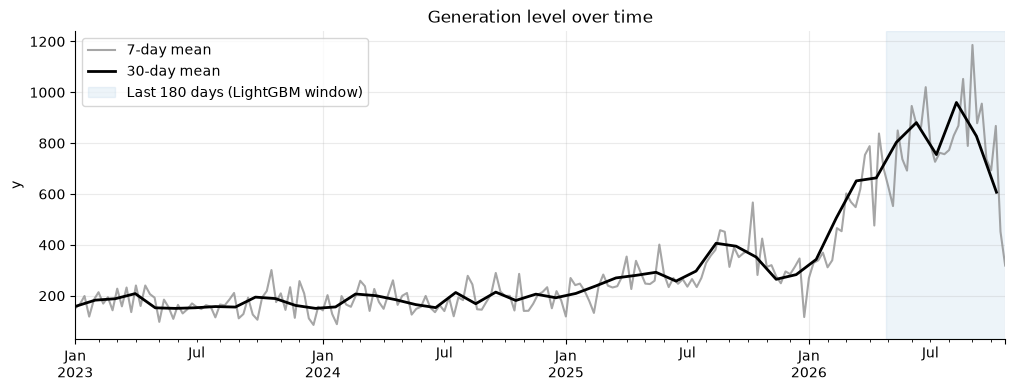

year,2023,2024,2025,2026
mean,171.0,184.0,291.0,684.0
median,155.0,166.0,262.0,451.0


In [3]:
series = data.set_index('ds').y
fig, ax = plt.subplots(figsize=(12, 4))
series.resample('7D').mean().plot(ax=ax, color='grey', alpha=0.7, label='7-day mean')
series.resample('30D').mean().plot(ax=ax, color='black', lw=2, label='30-day mean')
ax.axvspan(data.ds.iloc[-TRAIN_WINDOW_DAYS * DAY], data.ds.iloc[-1], color=MODEL_COLORS['weather'], alpha=0.08,
           label=f'Last {TRAIN_WINDOW_DAYS} days (LightGBM window)')
ax.set(title='Generation level over time', ylabel='y', xlabel='')
ax.legend(loc='upper left')
plt.show()

yearly = data.groupby(data.ds.dt.year)['y'].agg(['mean', 'median']).rename_axis('year')
display(yearly.round(0).T)

### 1.2 Daily shape: a solar peak on top of a night-time base

Each row is a month, each column an hour of the day. The bright midday band is the solar peak; it widens in summer and grows sharply in 2026. Night hours are not zero, so part of the generation does not depend on the sun.

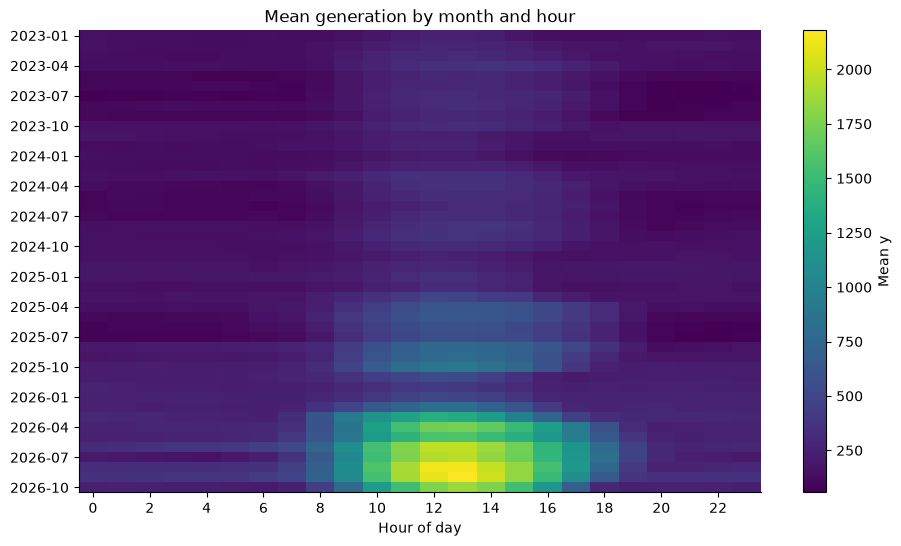

In [4]:
profile = (
    data.assign(month=data.ds.dt.to_period('M'), hour=data.ds.dt.hour)
    .pivot_table(index='month', columns='hour', values='y', aggfunc='mean')
)
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(profile.to_numpy(), aspect='auto', cmap='viridis')
ax.grid(False)
ax.set_yticks(range(0, len(profile), 3), [str(p) for p in profile.index[::3]])
ax.set_xticks(range(0, 24, 2))
ax.set(xlabel='Hour of day', title='Mean generation by month and hour')
fig.colorbar(im, ax=ax, label='Mean y')
plt.show()

### 1.3 Which weather columns move with generation?

Spearman correlation with `y` over the last 180 days, separately for daylight and night hours (`daylight` itself is left out because it is constant within each group). During the day, generation moves with humidity and temperature, which act as proxies for clear sunny weather; `cloud_cover` is coarse (only a few distinct values) and only weakly related. At night, wind speed is the strongest signal. This is the reason to expect weather features to help.

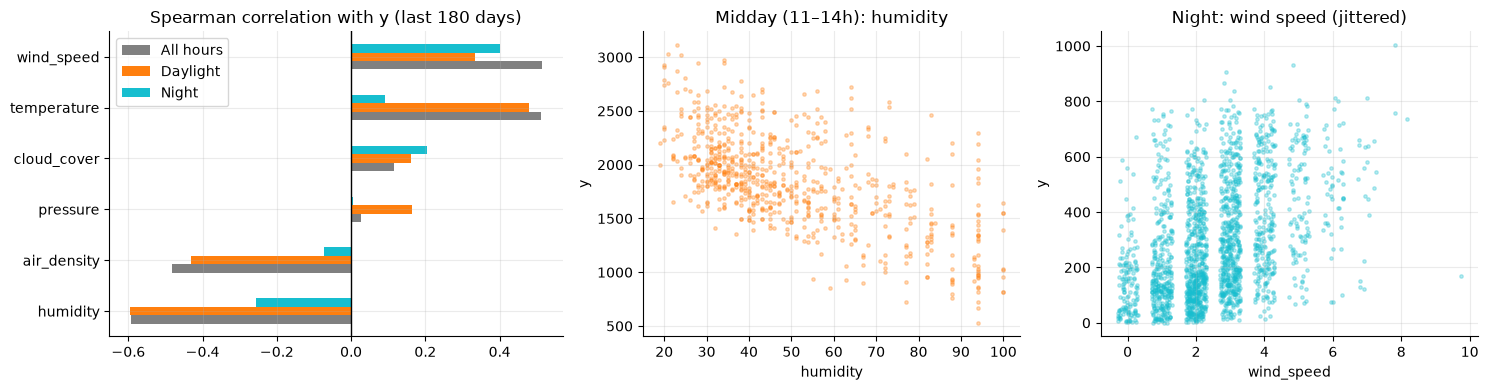

In [5]:
recent = data.iloc[-TRAIN_WINDOW_DAYS * DAY:]
varying = [c for c in WEATHER_COLUMNS if c != 'daylight']
day_hours, night = recent[recent.daylight == 1], recent[recent.daylight == 0]
correlations = pd.DataFrame({
    'All hours': recent[varying].corrwith(recent.y, method='spearman'),
    'Daylight': day_hours[varying].corrwith(day_hours.y, method='spearman'),
    'Night': night[varying].corrwith(night.y, method='spearman'),
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={'width_ratios': [1.2, 1, 1]})
correlations.sort_values('All hours').plot.barh(ax=axes[0], color=['grey', '#ff7f0e', '#17becf'])
axes[0].axvline(0, color='black', lw=1)
axes[0].set(title='Spearman correlation with y (last 180 days)', xlabel='')

midday = recent[recent.ds.dt.hour.between(11, 14)]
axes[1].scatter(midday.humidity, midday.y, s=6, alpha=0.3, color='#ff7f0e')
axes[1].set(title='Midday (11–14h): humidity', xlabel='humidity', ylabel='y')
axes[2].scatter(night.wind_speed + np.random.default_rng(SEED).uniform(-0.3, 0.3, len(night)), night.y,
                s=6, alpha=0.3, color='#17becf')
axes[2].set(title='Night: wind speed (jittered)', xlabel='wind_speed', ylabel='y')
plt.tight_layout()
plt.show()

## 2. Evaluation design

Every forecast is made from an **origin**: the model sees only data before it and predicts the next 48 hours.

- **Cross-validation (7 origins, 2 days apart):** used to compare models and to calibrate prediction intervals.
- **Holdout (last 14 days, 7 origins):** touched once, with all settings frozen.

At each origin LightGBM is refit on the previous 180 days and AutoETS on the previous 46 days. Seven CV windows are few: treat differences between models smaller than the fold-to-fold spread as noise.

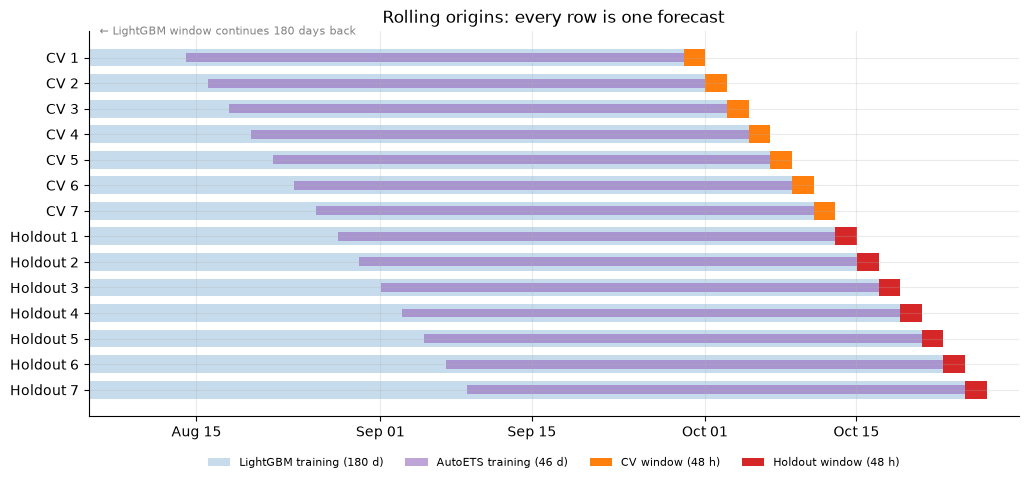

In [6]:
holdout_start = N - HOLDOUT_DAYS * DAY
holdout_origins = np.arange(holdout_start, N - H + 1, H, dtype=int)
cv_origins = holdout_start - H - np.arange(CV_N_FOLDS - 1, -1, -1) * H

first_training_origin = int(cv_origins[0]) - TRAIN_WINDOW_DAYS * DAY
if first_training_origin < MIN_ORIGIN:
    raise ValueError('Not enough history for this training window and CV schedule.')

stages = [('CV', o) for o in cv_origins] + [('Holdout', o) for o in holdout_origins]
fig, ax = plt.subplots(figsize=(12, 5))
for row, (stage, origin) in enumerate(stages):
    start = mdates.date2num(data.ds.iloc[origin])
    ax.barh(row, TRAIN_WINDOW_DAYS, left=start - TRAIN_WINDOW_DAYS, height=0.7,
            color=MODEL_COLORS['weather'], alpha=0.25, label='LightGBM training (180 d)' if row == 0 else None)
    ax.barh(row, ETS_TRAIN_DAYS, left=start - ETS_TRAIN_DAYS, height=0.35,
            color=MODEL_COLORS['autoets'], alpha=0.6, label='AutoETS training (46 d)' if row == 0 else None)
    ax.barh(row, H / DAY, left=start, height=0.7, color='tab:orange' if stage == 'CV' else 'tab:red',
            label={0: 'CV window (48 h)', CV_N_FOLDS: 'Holdout window (48 h)'}.get(row))

left_edge = mdates.date2num(data.ds.iloc[cv_origins[0]]) - 55
ax.set_xlim(left_edge, mdates.date2num(data.ds.iloc[-1]) + 3)
ax.text(left_edge + 1, -0.9, '← LightGBM window continues 180 days back', fontsize=8, color='grey')
ax.set_yticks(range(len(stages)), [f'{stage} {i % CV_N_FOLDS + 1}' for i, (stage, _) in enumerate(stages)])
ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_title('Rolling origins: every row is one forecast')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=8, frameon=False)
plt.show()

## 3. Features

Each training example is one origin with its 48 target hours (48 rows). Generation features use only values before the origin, so hour 30 cannot see the actual value of hour 6.

| Group | Features |
|---|---|
| Generation lags | same hour 1, 2 and 7 days ago; same hour averaged over the last 3 days; last-24h mean, last-7d mean and std, change between the last two days |
| Calendar | `hour`, `day_of_week`, `day_of_year`, `horizon` (forecast step 1–48) |
| Sun and clouds | `cloud_cover`, `daylight` |
| Wind | `wind_speed`, `air_density` |
| Other weather | `temperature`, `pressure`, `humidity` |

Weather columns are used as they are, without transformations.

In [7]:
all_features = make_features(y, N, future_weather).columns.tolist()
feature_groups = {
    'Generation lags': [c for c in all_features if c.startswith('last_') or c.endswith('_same_hour')],
    'Calendar': ['hour', 'day_of_week', 'day_of_year', 'horizon'],
    'Sun and clouds': ['cloud_cover', 'daylight'],
    'Wind': ['wind_speed', 'air_density'],
    'Other weather': ['temperature', 'pressure', 'humidity'],
}
assert sorted(sum(feature_groups.values(), [])) == sorted(all_features)

frames = []
for origin in range(first_training_origin, N - H + 1, TRAIN_ORIGIN_STEP):
    frame = make_features(y, origin, data.iloc[origin : origin + H])
    frame['origin'] = origin
    frame['target'] = y[origin : origin + H]
    frames.append(frame)
supervised = pd.concat(frames, ignore_index=True)

print(f'{len(supervised):,} rows from {len(frames)} origins, {len(all_features)} features')

9,936 rows from 207 origins, 19 features


## 4. Cross-validation

All three models forecast the same seven CV windows. The main score is **skill = RMSE / seasonal-naive RMSE** (below 1 means better than naive). Tables use the ratio of mean RMSEs, so one unusually easy window for naive cannot dominate the average; per-window plots show the ratio for each window. MAE is shown alongside RMSE. MAPE is not used: night values close to zero make it explode.

In [8]:
model_cache = {}
ets_cache = {}


def fit_lgbm(origin, excluded=()):
    """Fit on origins whose 48 target hours all end before this origin."""
    columns = [c for c in all_features if c not in excluded]
    key = (int(origin), tuple(columns))
    if key not in model_cache:
        mask = supervised.origin.between(origin - TRAIN_WINDOW_DAYS * DAY, origin - H)
        train = supervised.loc[mask]
        model_cache[key] = lgb.LGBMRegressor(**LGBM_PARAMS).fit(train[columns], train.target)
    return model_cache[key]


def predict(origin, model_key, target_weather=None):
    if target_weather is None:
        target_weather = data.iloc[origin : origin + H]
    if model_key == 'weather':
        X = make_features(y, origin, target_weather)[all_features]
        return np.maximum(fit_lgbm(origin).predict(X), 0)
    if model_key == 'autoets':
        if origin not in ets_cache:
            ets_cache[origin] = autoets(data, origin, ETS_TRAIN_DAYS)
        return ets_cache[origin]
    if model_key == 'naive':
        return seasonal_naive(y, origin)
    raise ValueError(f'Unknown model: {model_key}')


def score_rows(origin, model_key, point, lower=None, upper=None):
    actual = y[origin : origin + H]
    naive = seasonal_naive(y, origin)
    rows = []
    for part, sl in PARTS.items():
        row = {
            'origin': int(origin),
            'model_key': model_key,
            'model': MODEL_NAMES[model_key],
            'part': part,
            'RMSE': rmse(actual[sl], point[sl]),
            'MAE': mae(actual[sl], point[sl]),
            'RMSE / naive': rmse(actual[sl], point[sl]) / rmse(actual[sl], naive[sl]),
        }
        if lower is not None:
            inside = (actual[sl] >= lower[sl]) & (actual[sl] <= upper[sl])
            row.update({
                'coverage': inside.mean(),
                'width': np.mean(upper[sl] - lower[sl]),
                'Winkler': winkler(actual[sl], lower[sl], upper[sl]),
            })
        rows.append(row)
    return rows


def summarize(scores, metrics):
    """Mean of each metric per model and part; 'RMSE / naive' is the ratio of mean RMSEs."""
    values = sorted({m for m in metrics if m != 'RMSE / naive'} | {'RMSE'})
    table = scores.pivot_table(index='model', columns='part', values=values, aggfunc='mean')
    skill = table['RMSE'] / table.loc[MODEL_NAMES['naive'], 'RMSE']
    table = pd.concat([table, pd.concat({'RMSE / naive': skill}, axis=1)], axis=1)
    return table[metrics].reindex(index=list(MODEL_NAMES.values())).reindex(columns=list(PARTS), level=1)


cv_predictions = {key: {} for key in MODEL_NAMES}
cv_rows = []
for origin in cv_origins:
    for key in MODEL_NAMES:
        cv_predictions[key][origin] = predict(origin, key)
        cv_rows += score_rows(origin, key, cv_predictions[key][origin])
cv_scores = pd.DataFrame(cv_rows)

print('Mean over 7 CV windows')
display(summarize(cv_scores, ['RMSE / naive', 'RMSE', 'MAE']).round(2))

Mean over 7 CV windows


RMSE / naive                RMSE                     MAE  \
part                        1–24 25–48  1–48    1–24   25–48    1–48    1–24   
model                                                                          
LightGBM + weather*         0.85  0.82  0.83  282.84  245.96  267.62  231.32   
AutoETS                     0.84  1.19  1.03  277.29  357.58  329.97  226.28   
Seasonal naive              1.00  1.00  1.00  331.38  300.57  321.71  279.87   

                                     
part                  25–48    1–48  
model                                
LightGBM + weather*  193.49  212.40  
AutoETS              276.77  251.53  
Seasonal naive       236.86  258.36

### 4.1 How stable is the ranking across windows?

One dot per CV window. The averages above hide a wide spread: on some windows AutoETS wins, on others it is the worst model.

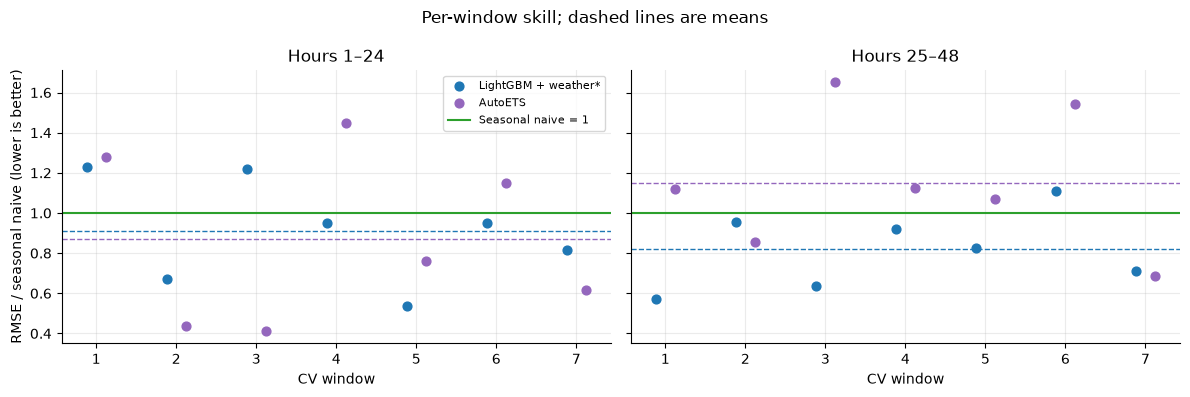

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
fold_numbers = np.arange(1, CV_N_FOLDS + 1)
for ax, part in zip(axes, DAY_PARTS):
    for offset, key in zip([-0.12, 0.12], ['weather', 'autoets']):
        values = cv_scores.query('model_key == @key and part == @part').set_index('origin')['RMSE / naive']
        values = values.reindex(cv_origins).to_numpy()
        ax.scatter(fold_numbers + offset, values, color=MODEL_COLORS[key], s=40, label=MODEL_NAMES[key], zorder=3)
        ax.axhline(values.mean(), color=MODEL_COLORS[key], ls='--', lw=1)
    ax.axhline(1, color=MODEL_COLORS['naive'], lw=1.5, label='Seasonal naive = 1')
    ax.set(title=f'Hours {part}', xlabel='CV window', xticks=fold_numbers)
axes[0].set_ylabel('RMSE / seasonal naive (lower is better)')
axes[0].legend(fontsize=8)
fig.suptitle('Per-window skill; dashed lines are means')
plt.tight_layout()
plt.show()

### 4.2 Every CV window

Grey: the last observed day. Shaded: the hidden 48 hours. The dotted line separates forecast day 1 from day 2. Titles show RMSE / naive over all 48 hours. Hourly values for each window are in `cv_tables[origin]`.

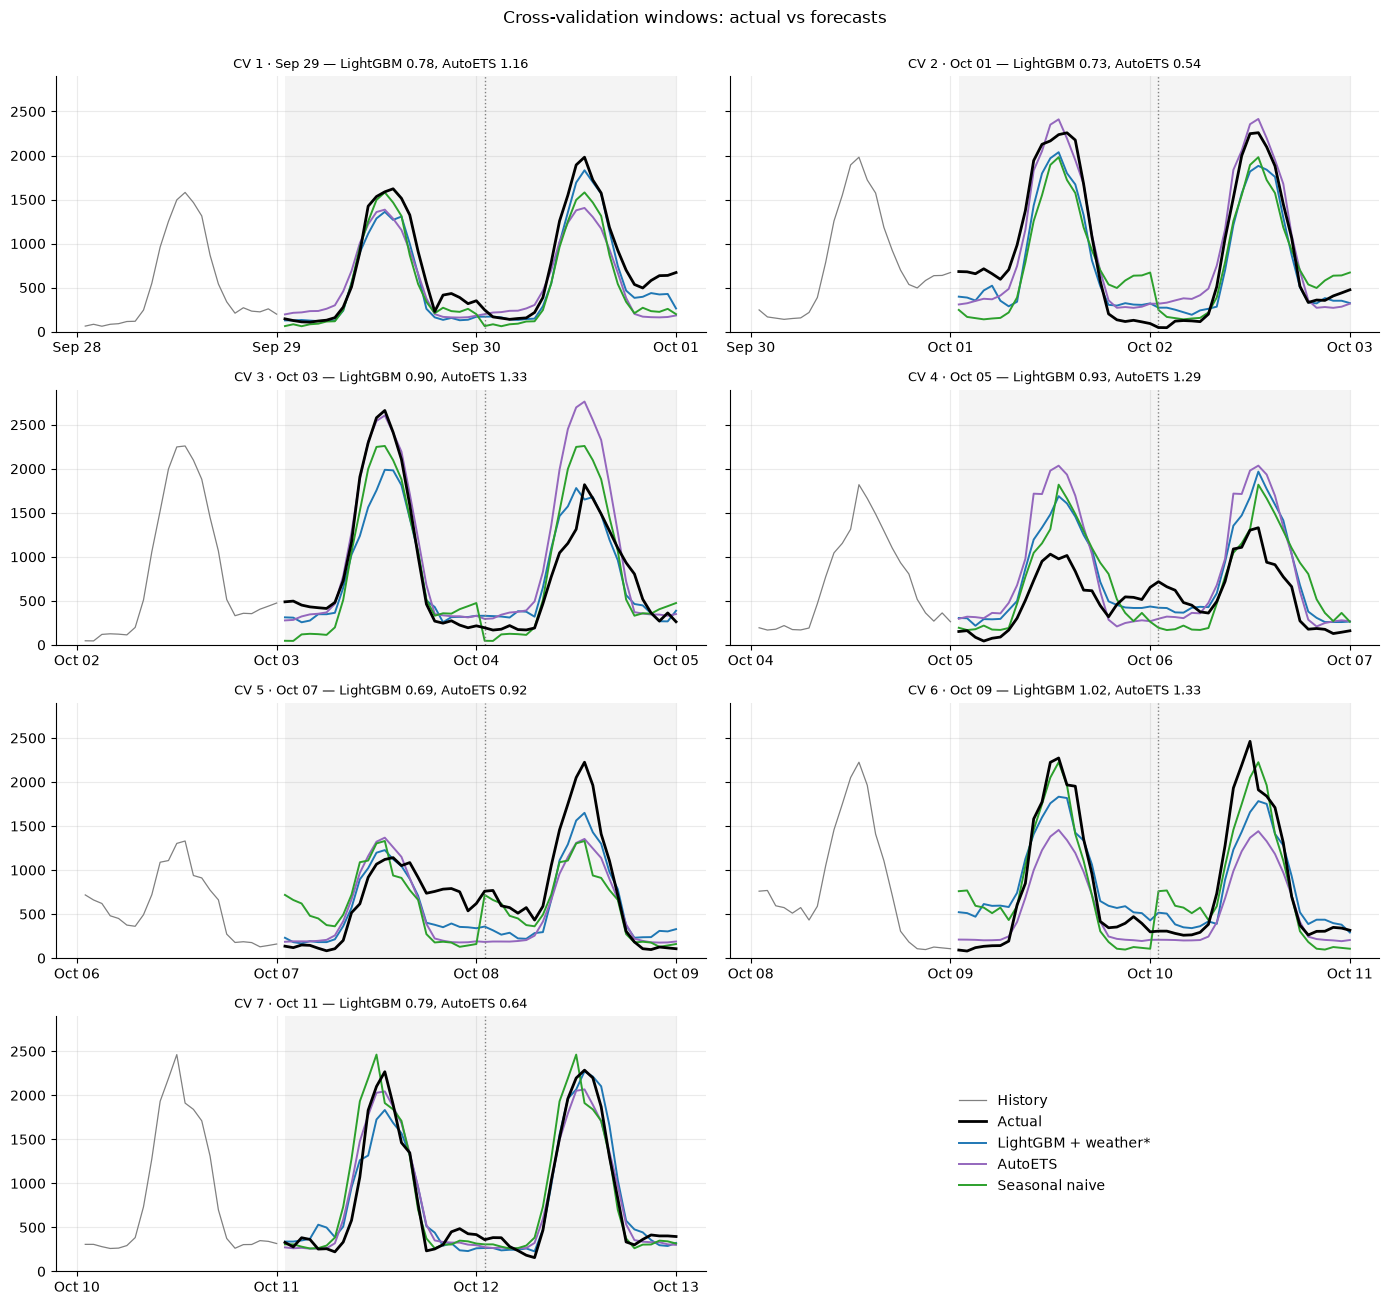

In [10]:
def window_title(scores, origin, prefix):
    skill = scores.query('origin == @origin and part == "1–48"').set_index('model_key')['RMSE / naive']
    return (f'{prefix} · {data.ds.iloc[origin]:%b %d} — LightGBM {skill["weather"]:.2f}, '
            f'AutoETS {skill["autoets"]:.2f}')


fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharey=True)
plot_window_grid(
    fig, axes, data.ds, y, cv_origins,
    {o: {k: cv_predictions[k][o] for k in MODEL_NAMES} for o in cv_origins},
    [window_title(cv_scores, o, f'CV {i}') for i, o in enumerate(cv_origins, start=1)],
)
fig.suptitle('Cross-validation windows: actual vs forecasts', y=1.0)
plt.tight_layout()
plt.show()

cv_tables = {
    o: pd.DataFrame({'ds': data.ds.iloc[o : o + H].to_numpy(), 'actual': y[o : o + H]}
                    | {MODEL_NAMES[k]: cv_predictions[k][o] for k in MODEL_NAMES})
    for o in cv_origins
}

## 5. Prediction intervals and the final holdout

**Intervals.** For each model, take its absolute CV errors and use their 95th percentile as a symmetric half-width. Errors are split by forecast day (1–24, 25–48) and by the `daylight` flag, which is known in advance: night errors are smaller, so the night band is narrower. Seasonal naive gets the same treatment, which keeps the interval comparison fair.

This is an empirical baseline with 7 × 48 calibration errors per model, not a coverage guarantee.

In [11]:
halfwidths = {key: calibrate_halfwidths(y, daylight, cv_origins, cv_predictions[key]) for key in MODEL_NAMES}
display(
    pd.DataFrame(halfwidths).T.rename(index=MODEL_NAMES)
    .rename(columns=lambda flag: 'day' if flag else 'night', level=1)
    .round(0)
)

1–24         25–48       
                     night    day  night    day
LightGBM + weather*  431.0  674.0  367.0  700.0
AutoETS              430.0  919.0  472.0  996.0
Seasonal naive       597.0  686.0  474.0  844.0

**Holdout.** The same models and interval widths, frozen, on the last 14 days. Coverage should be near 0.95. The Winkler score combines width with a penalty for every miss (lower is better).

In [12]:
holdout_forecasts = {}
holdout_rows = []
for origin in holdout_origins:
    holdout_forecasts[origin] = {}
    for key in MODEL_NAMES:
        point = predict(origin, key)
        lower, upper = interval(point, daylight[origin : origin + H], halfwidths[key])
        holdout_forecasts[origin][key] = (point, lower, upper)
        holdout_rows += score_rows(origin, key, point, lower, upper)
holdout_scores = pd.DataFrame(holdout_rows)

print('Mean over 7 holdout windows')
display(summarize(holdout_scores, ['RMSE / naive', 'RMSE', 'MAE']).round(2))
display(summarize(holdout_scores, ['coverage', 'width', 'Winkler']).round(2))

Mean over 7 holdout windows


RMSE / naive                RMSE                     MAE  \
part                        1–24 25–48  1–48    1–24   25–48    1–48    1–24   
model                                                                          
LightGBM + weather*         1.28  0.88  1.00  245.68  278.14  265.73  200.08   
AutoETS                     1.84  1.36  1.49  352.75  428.90  397.59  246.97   
Seasonal naive              1.00  1.00  1.00  192.12  314.59  266.91  153.53   

                                     
part                  25–48    1–48  
model                                
LightGBM + weather*  240.13  220.10  
AutoETS              335.90  291.44  
Seasonal naive       251.09  202.31

coverage               width                    Winkler  \
part                    1–24 25–48  1–48    1–24    25–48     1–48     1–24   
model                                                                         
LightGBM + weather*     0.99  0.89  0.94  919.06   913.79   916.43   932.64   
AutoETS                 0.92  0.85  0.89  996.12  1064.06  1030.09  1810.82   
Seasonal naive          0.99  0.92  0.96  984.78  1013.59   999.18   991.64   

                                       
part                   25–48     1–48  
model                                  
LightGBM + weather*  1171.67  1052.15  
AutoETS              2817.71  2314.27  
Seasonal naive       1963.45  1477.54

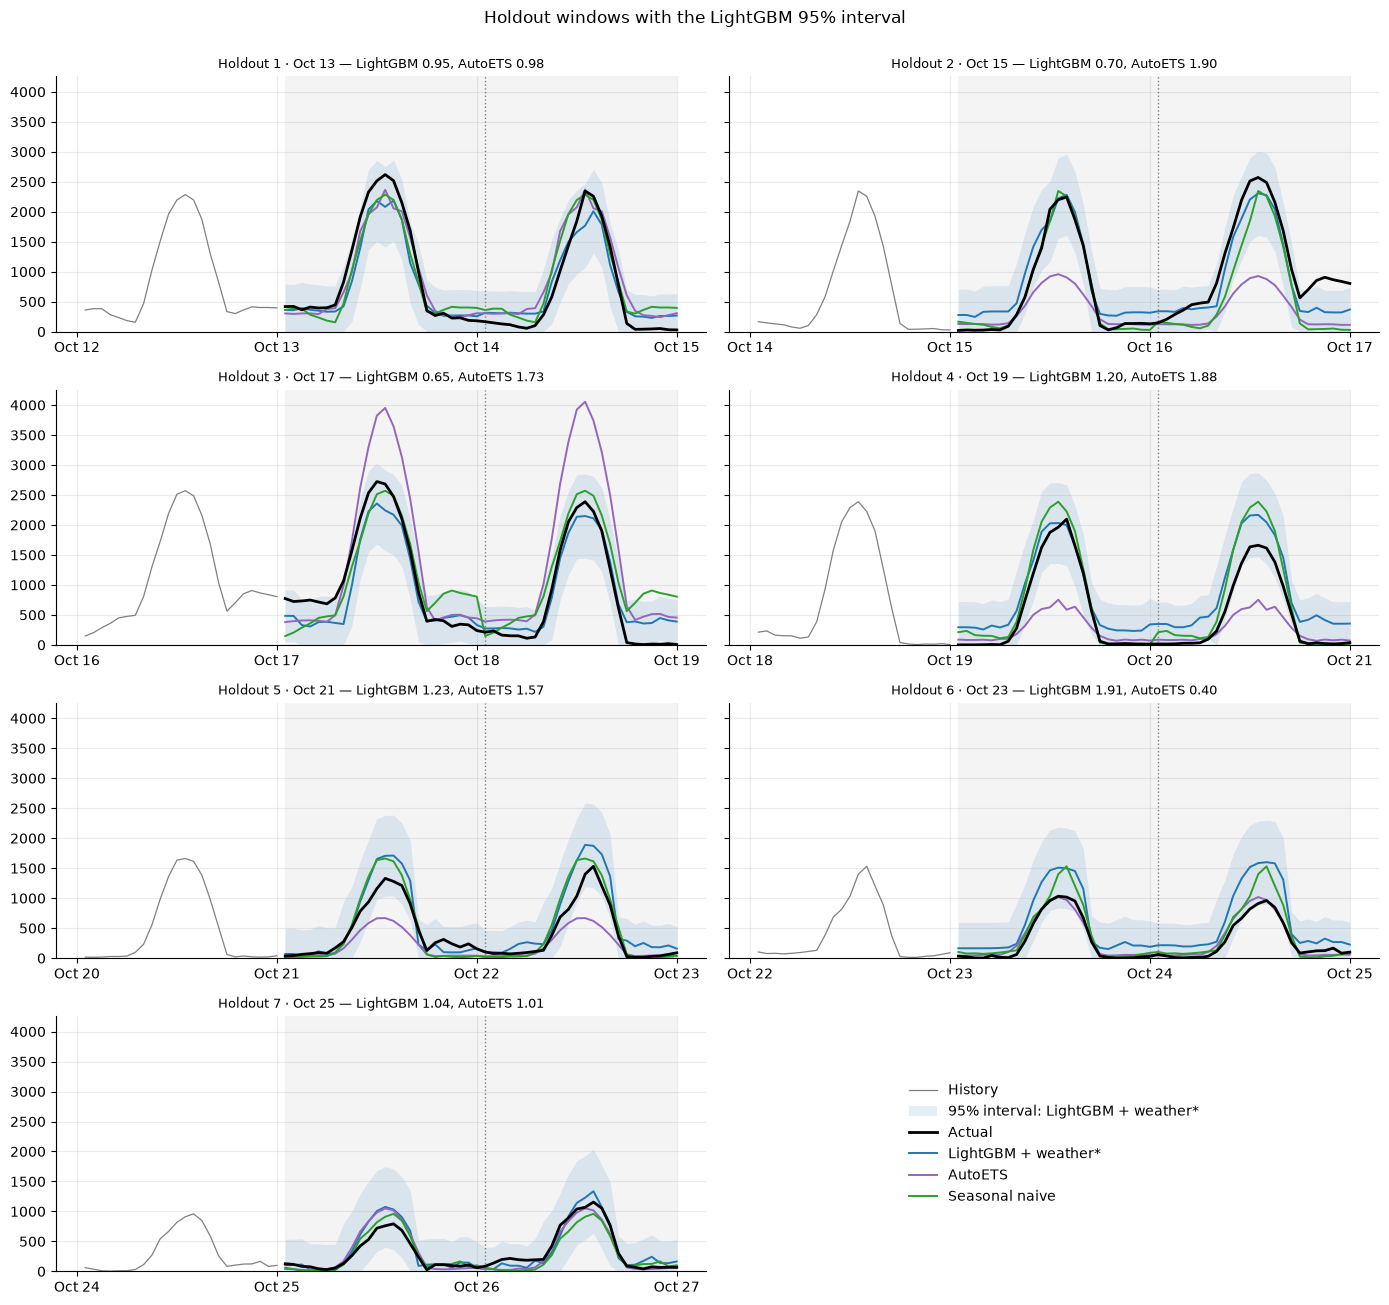

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharey=True)
plot_window_grid(
    fig, axes, data.ds, y, holdout_origins,
    {o: {k: holdout_forecasts[o][k][0] for k in MODEL_NAMES} for o in holdout_origins},
    [window_title(holdout_scores, o, f'Holdout {i}') for i, o in enumerate(holdout_origins, start=1)],
    bands={o: ('weather', *holdout_forecasts[o]['weather'][1:]) for o in holdout_origins},
)
fig.suptitle('Holdout windows with the LightGBM 95% interval', y=1.0)
plt.tight_layout()
plt.show()

### 5.1 Which windows and which forecast day?

Each cell is RMSE / naive for one holdout window. Blue is better than naive, red is worse.

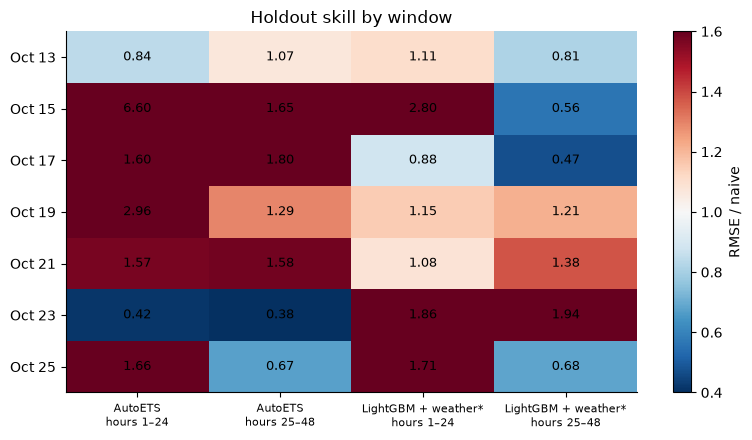

In [14]:
skill = (
    holdout_scores.query('model_key != "naive" and part != "1–48"')
    .pivot_table(index='origin', columns=['model_key', 'part'], values='RMSE / naive')
)
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(skill.to_numpy(), cmap='RdBu_r', vmin=0.4, vmax=1.6, aspect='auto')
ax.grid(False)
ax.set_xticks(range(skill.shape[1]), [f'{MODEL_NAMES[k]}\nhours {p}' for k, p in skill.columns], fontsize=8)
ax.set_yticks(range(len(skill)), [f'{data.ds.iloc[o]:%b %d}' for o in skill.index])
for i in range(skill.shape[0]):
    for j in range(skill.shape[1]):
        ax.text(j, i, f'{skill.iat[i, j]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, label='RMSE / naive')
ax.set_title('Holdout skill by window')
plt.tight_layout()
plt.show()

### 5.2 Error by forecast hour and interval quality

Left: RMSE for each of the 48 steps, averaged over holdout windows. Peaks come from midday hours. Right: each point is one model and forecast day; the best interval is close to the dashed 0.95 line with the smallest width.

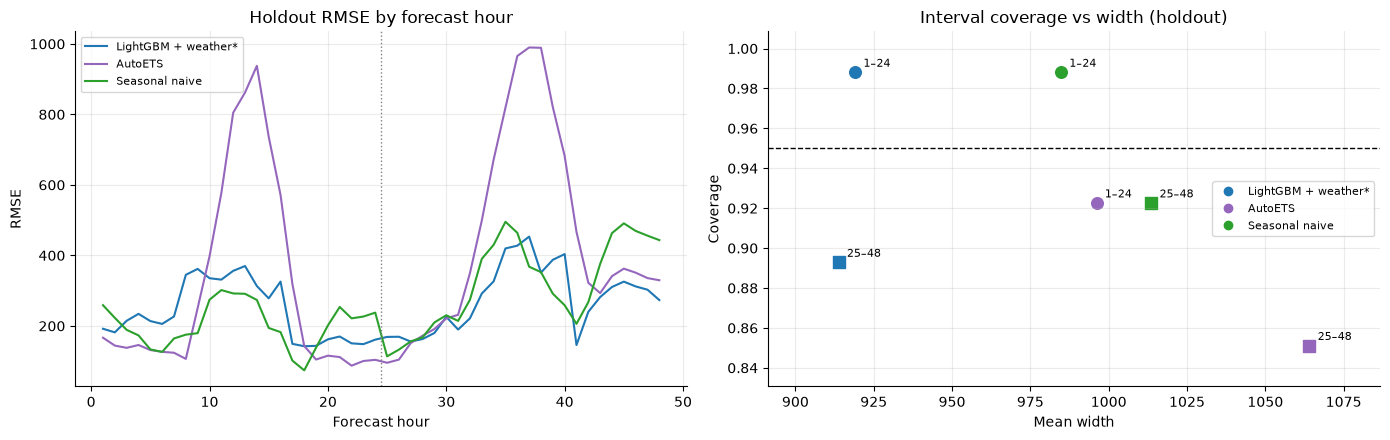

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
steps = np.arange(1, H + 1)
for key in MODEL_NAMES:
    errors = np.stack([y[o : o + H] - holdout_forecasts[o][key][0] for o in holdout_origins])
    axes[0].plot(steps, np.sqrt(np.mean(errors ** 2, axis=0)), color=MODEL_COLORS[key], label=MODEL_NAMES[key])
axes[0].axvline(DAY + 0.5, color='grey', ls=':', lw=1)
axes[0].set(title='Holdout RMSE by forecast hour', xlabel='Forecast hour', ylabel='RMSE')
axes[0].legend(fontsize=8)

interval_table = summarize(holdout_scores, ['coverage', 'width'])
for key, name in MODEL_NAMES.items():
    for part, marker in zip(DAY_PARTS, ['o', 's']):
        x, c = interval_table.loc[name, ('width', part)], interval_table.loc[name, ('coverage', part)]
        axes[1].scatter(x, c, color=MODEL_COLORS[key], marker=marker, s=70)
        axes[1].annotate(f'{part}', (x, c), xytext=(6, 4), textcoords='offset points', fontsize=8)
axes[1].axhline(0.95, color='black', ls='--', lw=1)
axes[1].set(title='Interval coverage vs width (holdout)', xlabel='Mean width', ylabel='Coverage')
handles = [plt.Line2D([], [], color=MODEL_COLORS[k], marker='o', ls='', label=n) for k, n in MODEL_NAMES.items()]
axes[1].legend(handles=handles, fontsize=8, loc='center right')
axes[1].margins(0.15)
plt.tight_layout()
plt.show()

## 6. What drives LightGBM

### 6.1 Permutation importance

Shuffle one feature, predict again with the same fitted models, and measure how much RMSE grows. Rows from all seven CV windows are pooled before shuffling. This matters: origin-level features such as `last_7d_mean` are constant within one window, so shuffling inside a single window would leave them unchanged and report zero importance by construction.

Correlated features share credit (the four same-hour lags overlap), so a small bar does not mean a feature is useless.

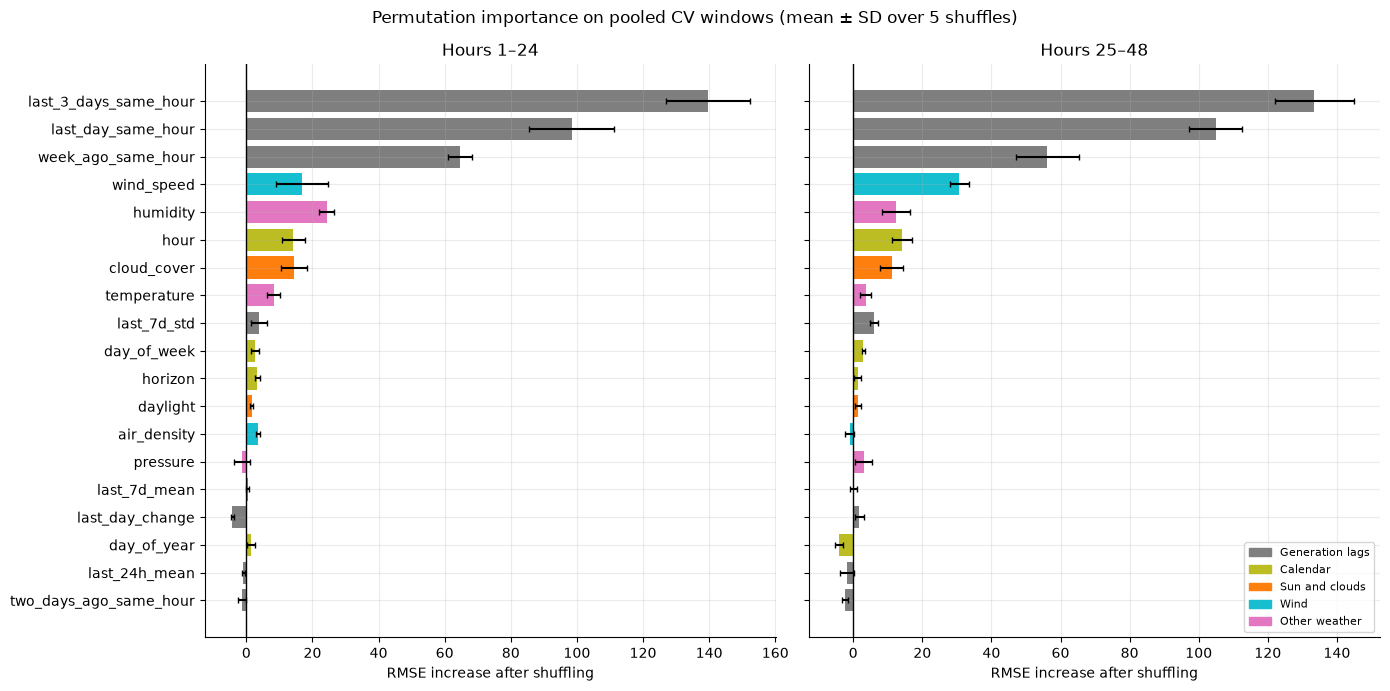

In [16]:
GROUP_COLORS = {
    'Generation lags': '#7f7f7f',
    'Calendar': '#bcbd22',
    'Sun and clouds': '#ff7f0e',
    'Wind': '#17becf',
    'Other weather': '#e377c2',
}
feature_group = {f: g for g, features in feature_groups.items() for f in features}

cv_inputs = pd.concat(
    {o: make_features(y, o, data.iloc[o : o + H])[all_features] for o in cv_origins}, names=['origin', 'row']
)


def pooled_rmse(X):
    """RMSE per forecast day over all CV windows, each window predicted by its own model."""
    errors = {part: [] for part in DAY_PARTS}
    for origin in cv_origins:
        point = np.maximum(fit_lgbm(origin).predict(X.loc[origin]), 0)
        for part in DAY_PARTS:
            sl = PARTS[part]
            errors[part].append(y[origin : origin + H][sl] - point[sl])
    return {part: float(np.sqrt(np.mean(np.concatenate(e) ** 2))) for part, e in errors.items()}


base_rmse = pooled_rmse(cv_inputs)
rng = np.random.default_rng(SEED)
permutation_rows = []
for feature in all_features:
    for repeat in range(PERMUTATION_REPEATS):
        shuffled = cv_inputs.copy()
        shuffled[feature] = rng.permutation(shuffled[feature].to_numpy())
        for part, value in pooled_rmse(shuffled).items():
            permutation_rows.append({'feature': feature, 'part': part, 'delta_RMSE': value - base_rmse[part]})

importance = pd.DataFrame(permutation_rows).groupby(['feature', 'part']).delta_RMSE.agg(['mean', 'std'])
order = importance['mean'].groupby('feature').mean().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for ax, part in zip(axes, DAY_PARTS):
    sub = importance.xs(part, level='part').reindex(order)
    ax.barh(sub.index, sub['mean'], xerr=sub['std'], capsize=2,
            color=[GROUP_COLORS[feature_group[f]] for f in sub.index])
    ax.axvline(0, color='black', lw=1)
    ax.set(title=f'Hours {part}', xlabel='RMSE increase after shuffling')
handles = [plt.Rectangle((0, 0), 1, 1, color=c, label=g) for g, c in GROUP_COLORS.items()]
axes[1].legend(handles=handles, loc='lower right', fontsize=8)
fig.suptitle(f'Permutation importance on pooled CV windows (mean ± SD over {PERMUTATION_REPEATS} shuffles)')
plt.tight_layout()
plt.show()

### 6.2 Removing a whole group

Refit LightGBM without one feature group and compare RMSE on the CV windows. This avoids the shared-credit problem: if removing *Wind* hurts, no other feature can stand in for it. Bars are means over the seven windows, whiskers are standard errors (SD / √7). A whisker that crosses zero means the group's effect is not distinguishable from window-to-window noise.

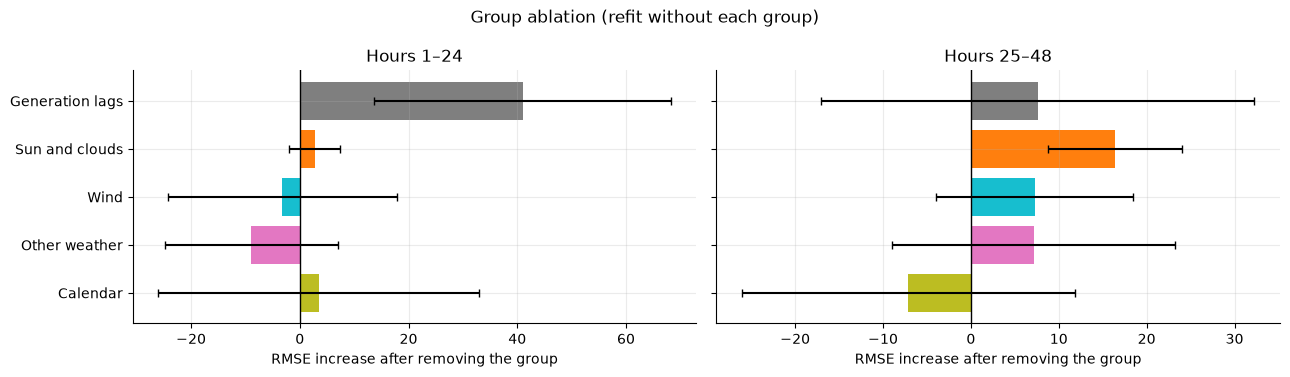

In [17]:
ablation_rows = []
for group, removed in feature_groups.items():
    for origin in cv_origins:
        X = cv_inputs.loc[origin].drop(columns=removed)
        reduced = np.maximum(fit_lgbm(origin, excluded=removed).predict(X), 0)
        full = cv_predictions['weather'][origin]
        actual = y[origin : origin + H]
        for part in DAY_PARTS:
            sl = PARTS[part]
            ablation_rows.append({'group': group, 'part': part,
                                  'delta_RMSE': rmse(actual[sl], reduced[sl]) - rmse(actual[sl], full[sl])})

ablation = pd.DataFrame(ablation_rows).groupby(['group', 'part']).delta_RMSE.agg(['mean', 'sem'])
group_order = ablation['mean'].groupby('group').mean().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, part in zip(axes, DAY_PARTS):
    sub = ablation.xs(part, level='part').reindex(group_order)
    ax.barh(sub.index, sub['mean'], xerr=sub['sem'], capsize=3, color=[GROUP_COLORS[g] for g in sub.index])
    ax.axvline(0, color='black', lw=1)
    ax.set(title=f'Hours {part}', xlabel='RMSE increase after removing the group')
fig.suptitle('Group ablation (refit without each group)')
plt.tight_layout()
plt.show()

### 6.3 How much does perfect weather flatter LightGBM?

Historical scores use observed weather. A real forecast would be wrong by some amount. Here Gaussian noise is added to the weather inputs of the CV windows, with standard deviation equal to a fraction of each column's spread over the last 180 days, and the fitted models predict again. `daylight` is left untouched because it is known exactly in advance.

This is a rough stress test, not a model of real forecast errors, but it shows how much of the advantage over naive survives imperfect weather.

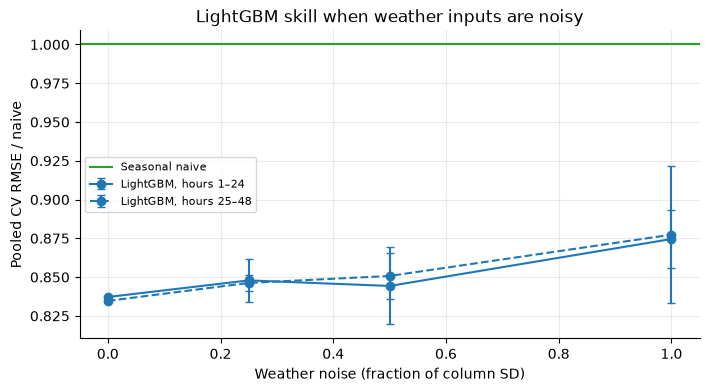

In [18]:
noisy_columns = [c for c in WEATHER_COLUMNS if c != 'daylight']
column_sd = data[noisy_columns].iloc[-TRAIN_WINDOW_DAYS * DAY:].std()
naive_rmse = {
    part: rmse(np.concatenate([y[o : o + H][PARTS[part]] for o in cv_origins]),
               np.concatenate([seasonal_naive(y, o)[PARTS[part]] for o in cv_origins]))
    for part in DAY_PARTS
}

noise_rows = []
for level in WEATHER_NOISE_LEVELS:
    for repeat in range(PERMUTATION_REPEATS):
        noisy = cv_inputs.copy()
        noisy[noisy_columns] += rng.normal(0, 1, (len(noisy), len(noisy_columns))) * (level * column_sd).to_numpy()
        for part, value in pooled_rmse(noisy).items():
            noise_rows.append({'level': level, 'part': part, 'skill': value / naive_rmse[part]})
noise = pd.DataFrame(noise_rows).groupby(['level', 'part']).skill.agg(['mean', 'std']).unstack('part')

fig, ax = plt.subplots(figsize=(8, 4))
for part, ls in zip(DAY_PARTS, ['-', '--']):
    ax.errorbar(noise.index, noise[('mean', part)], yerr=noise[('std', part)], ls=ls, marker='o',
                color=MODEL_COLORS['weather'], capsize=3, label=f'LightGBM, hours {part}')
ax.axhline(1, color=MODEL_COLORS['naive'], lw=1.5, label='Seasonal naive')
ax.set(xlabel='Weather noise (fraction of column SD)', ylabel='Pooled CV RMSE / naive',
       title='LightGBM skill when weather inputs are noisy')
ax.legend(fontsize=8)
plt.show()

## 7. Forecast for the next 48 hours

Each model is refit at the last observed hour. LightGBM receives the weather forecast from `data/weather_forecast.csv`; generation inputs stop at the end of `data/train.csv`. This is a preview only: no submission file is written.

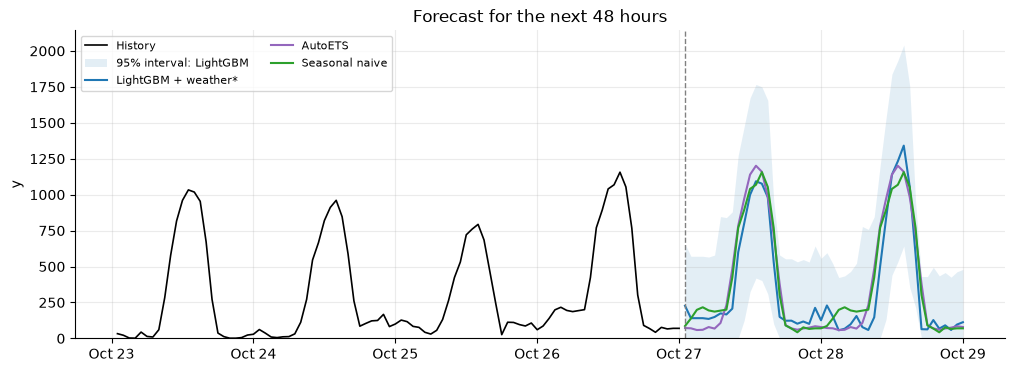

In [19]:
future_daylight = future_weather.daylight.to_numpy(dtype=int)
future_forecasts = {}
for key in MODEL_NAMES:
    point = predict(N, key, target_weather=future_weather)
    future_forecasts[key] = (point, *interval(point, future_daylight, halfwidths[key]))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(data.ds.iloc[-4 * DAY:], y[-4 * DAY:], color='black', lw=1.2, label='History')
point, lower, upper = future_forecasts['weather']
ax.fill_between(future_weather.ds, lower, upper, color=MODEL_COLORS['weather'], alpha=0.12, lw=0,
                label='95% interval: LightGBM')
for key, (point, _, _) in future_forecasts.items():
    ax.plot(future_weather.ds, point, color=MODEL_COLORS[key], label=MODEL_NAMES[key])
ax.axvline(future_weather.ds.iloc[0], color='grey', ls='--', lw=1)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set(title='Forecast for the next 48 hours', ylabel='y', xlabel='')
ax.set_ylim(bottom=0)
ax.legend(ncol=2, fontsize=8)
plt.show()

forecast_preview = pd.DataFrame({'ds': future_weather.ds} | {MODEL_NAMES[k]: f[0] for k, f in future_forecasts.items()})

## 8. Summary and conclusions

Skill is RMSE / seasonal naive (below 1 is better). Holdout interval columns are averaged over all 48 hours.

In [20]:
summary = pd.concat({
    'CV skill': summarize(cv_scores, ['RMSE / naive'])['RMSE / naive'],
    'Holdout skill': summarize(holdout_scores, ['RMSE / naive'])['RMSE / naive'],
    'Holdout interval': summarize(holdout_scores, ['coverage', 'Winkler']).xs('1–48', axis=1, level='part'),
}, axis=1)
display(summary.round(2))

CV skill             Holdout skill              \
                        1–24 25–48  1–48          1–24 25–48  1–48   
model                                                                
LightGBM + weather*     0.85  0.82  0.83          1.28  0.88  1.00   
AutoETS                 0.84  1.19  1.03          1.84  1.36  1.49   
Seasonal naive          1.00  1.00  1.00          1.00  1.00  1.00   

                    Holdout interval           
                            coverage  Winkler  
model                                          
LightGBM + weather*             0.94  1052.15  
AutoETS                         0.89  2314.27  
Seasonal naive                  0.96  1477.54

**Caveats**
- LightGBM scores use observed weather (Section 6.3 shows the sensitivity to weather errors).
- Seven windows per stage are few; the fold-to-fold spread in Section 4.1 is as large as the gaps between models.
- The holdout falls on a sharply declining level (Section 1.1), which favours models that react fast to the last day.
- LightGBM and AutoETS differ in both algorithm and training-window length, so the comparison is between two full setups, not two algorithms.

**Conclusions**

TODO: write 3–5 conclusions from the summary table and the plots above.